# Syllables and neuromodulators: effects, not just correlations

New analyses of what each neuromodulator's photometry signal tracks in behaviour. Built on `Functions/nm_syllables.py`, which reads only the photometry export (`pose_qc_hmm_k4`) and the 30 Hz states files. The old `event_psth.py` and `syllable_photometry.py` modules are not needed.

**Plan**
0. **Loader, checked** (this version): reproduce notebook 6's cached raw correlation maps.
1. **Effect sizes** instead of r: Δz and partial β, next to each feature's base rate, so the maps stop tracking how common a syllable is.
2. **Joint model**: all features at once, and syllable identity against continuous vigor (paw speed, wheel speed, whisker ME, licks).
3. **Syllable-onset responses by context** (epoch × outcome): the movement itself, or gated by the task?
4. **Encoding model**: task-event and movement kernels, unique cross-validated variance, interaction terms.

**Development data**: only one states file is on this machine for now (VTA-DA, ZFM-08828, 813e8682). Every step runs per fiber-session and caches its result, so scaling up means pointing at the full states folder.

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'nm_syllables.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from Functions import nm_syllables as ns
for msg in ['Mean of empty slice', 'Degrees of freedom', 'invalid value encountered', 'divide by zero']:
    warnings.filterwarnings('ignore', message=msg)

CACHE = ns.DATA / 'syllables_photometry'
rec = ns.load_recordings()
print(f'{len(rec)} fibers in {rec["eid"].nunique()} sessions have a states file')
rec[['eid', 'subject', 'target_NM', 'brain_region', 'hemisphere', 'session_type']]

1 fibers in 1 sessions have a states file


,eid,subject,target_NM,brain_region,hemisphere,session_type
0,813e8682-99dd-4642-b098-f1a12f2205cb,ZFM-08828,VTA-DA,VTA,r,biased


## 0. The loader reproduces notebook 6

The cached maps were pickled under numpy 2. The shim below lets numpy 1.x read them. For every fiber here, raw r maps are recomputed (factored features: 8 paw states, whisking, licking), and their Fisher z is compared with `corr_factored_raw`. They should agree to float32 precision, with the same blank samples.

In [2]:
def read_numpy2_pickle(path):
    try:
        import numpy._core.numeric  # noqa: F401  (numpy >= 2)
    except ImportError:
        for m in ['', '.numeric', '.multiarray', '._multiarray_umath']:
            sys.modules['numpy._core' + m] = __import__('numpy.core' + m, fromlist=['x'])
    return pd.read_pickle(path)

cached = read_numpy2_pickle(CACHE / f'corr_factored_raw_{ns.RUN}.pkl')
FIBERS = {eid: ns.load_session(eid) for eid in rec['eid'].unique()}
rows = []
for eid, fibers in FIBERS.items():
    for fiber in fibers:
        new = ns.correlation_maps(fiber)
        for _, r in new.iterrows():
            old = cached[(cached['eid'] == eid) & (cached['region'] == r['region']) & (cached['outcome'] == r['outcome'])].iloc[0]
            for w in ['z_stim', 'z_fb']:
                rows.append({'eid': eid[:8], 'region': r['region'], 'outcome': r['outcome'], 'window': w[2:],
                             'n_trials': (r['n_trials'], old['n_trials']),
                             'same blanks': bool((np.isnan(r[w]) == np.isnan(old[w])).all()),
                             'max |Δz|': np.nanmax(np.abs(r[w] - old[w])), 'valid cells': int((~np.isnan(r[w])).sum())})
pd.DataFrame(rows)

,eid,region,outcome,window,n_trials,same blanks,max |Δz|,valid cells
0,813e8682,VTA,0.0,stim,"(424, 424)",True,1.297072e-08,78
1,813e8682,VTA,0.0,fb,"(424, 424)",True,2.200905e-08,91
2,813e8682,VTA,1.0,stim,"(762, 762)",True,1.807673e-08,191
3,813e8682,VTA,1.0,fb,"(762, 762)",True,1.818522e-08,197


## Syllable coverage per fiber

A trial counts only where it has a syllable code. In the development session, the states file stops at trial 86 of 1186 (55–425 s of a 4960 s session). The cached maps had the same gap, so this is upstream on the analysis machine, not a copying error. Once the full folder is here, this table flags other short files: fibers with low coverage contribute few trials to every analysis.

In [3]:
cov = []
for eid, fibers in FIBERS.items():
    for f in fibers:
        m = f['meta']
        has = (~np.isnan(f['stim']['code']) & ~np.isnan(f['stim']['photometry'])).any(1)
        cov.append({'eid': eid[:8], 'region': f['region'], 'target_NM': m['target_NM'].iat[0], 'go trials': len(m),
                    'with syllables': int(has.sum()), 'rewarded': int(m.loc[has, 'correct'].sum()),
                    'errors': int((1 - m.loc[has, 'correct']).sum())})
pd.DataFrame(cov)

,eid,region,target_NM,go trials,with syllables,rewarded,errors
0,813e8682,VTA,VTA-DA,1186,87,61,26


## 1. Effect sizes instead of r

For a 0/1 feature, r = Δz / sd(z) · √(p(1−p)). Here Δz is the difference in mean photometry between trials with and without the feature, and p is the feature's base rate at that sample. So r shrinks wherever a feature is very common or very rare, even when its effect on the signal is unchanged. `ns.effect_maps` keeps the pieces apart. Each one is computed per fiber-session, outcome, window, feature and sample:

| | |
|---|---|
| `p` | base rate: the fraction of trials in the feature |
| `r` | point-biserial r, as in notebook 6 |
| `dz` | Δz, in z-scored GCaMP units. It does not depend on p |
| `d` | Δz / sd(z) = r / √(p(1−p)): r with the base rate taken out |
| `beta`, `t` | Δz with covariates held fixed (OLS). `task` = log response RT, \|contrast\| level, trial position and position² (notebook 6's set). `extended` adds previous outcome, choice side and block congruence |

A sample is kept only with ≥ 20 trials and ≥ 5 on each side of the feature, as before.

VTA-DA ZFM-08828 · rewarded trials (61 with syllables at most)


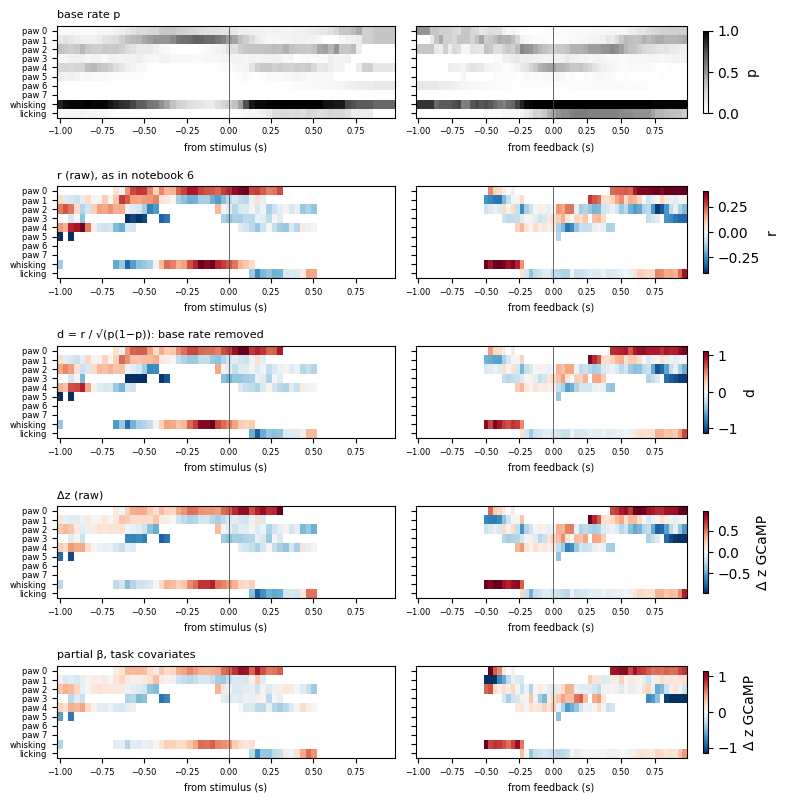

In [4]:
PAL = ns.load_palette()
FIBER = FIBERS[rec['eid'].iat[0]][0]
EM = {cov: ns.effect_maps(FIBER, covariates=cov) for cov in ('task', 'extended')}
NAMES = EM['task'].attrs['features']
TIME = FIBER['time']

def map_pair(fig, spec, A, title, cmap='RdBu_r', lim=None, cbar_label=''):
    # one row: stimulus-aligned | feedback-aligned map of an (F x T) pair, shared colour scale
    lim = lim if lim is not None else np.nanpercentile(np.abs(np.concatenate([a.ravel() for a in A])), 98)
    vmin = 0 if cmap != 'RdBu_r' else -lim
    sub = spec.subgridspec(1, 2, wspace=0.06)
    h = (TIME[1] - TIME[0]) / 2
    for k, (a, lab) in enumerate(zip(A, ['from stimulus (s)', 'from feedback (s)'])):
        ax = fig.add_subplot(sub[k])
        im = ax.imshow(a, aspect='auto', cmap=cmap, vmin=vmin, vmax=lim, interpolation='nearest',
                       extent=(TIME[0] - h, TIME[-1] + h, len(a) - 0.5, -0.5))
        ax.axvline(0, color='0.3', lw=0.6)
        ax.set_yticks(range(len(NAMES)), NAMES if k == 0 else [], fontsize=6)
        ax.set_xlabel(lab, fontsize=7); ax.tick_params(labelsize=6)
        if k == 0:
            ax.set_title(title, fontsize=8, loc='left')
    fig.colorbar(im, ax=ax, shrink=0.9, label=cbar_label)

def effect_figure(row, metrics):
    fig = plt.figure(figsize=(9, 1.9 * len(metrics)))
    gs = fig.add_gridspec(len(metrics), 1, hspace=0.75)
    for i, (col, title, cmap, label) in enumerate(metrics):
        map_pair(fig, gs[i], [row[f'{col}_stim'], row[f'{col}_fb']], title, cmap=cmap, cbar_label=label)
    plt.show()

METRICS = [('p', 'base rate p', 'Greys', 'p'), ('r', 'r (raw), as in notebook 6', 'RdBu_r', 'r'),
           ('d', 'd = r / √(p(1−p)): base rate removed', 'RdBu_r', 'd'),
           ('dz', 'Δz (raw)', 'RdBu_r', 'Δ z GCaMP'), ('beta', 'partial β, task covariates', 'RdBu_r', 'Δ z GCaMP')]
row = EM['task'].query('outcome == 1').iloc[0]
print(f"{row['target_NM']} {row['subject']} · rewarded trials ({int(np.nanmax(row['n_stim']))} with syllables at most)")
effect_figure(row, METRICS)

### Where r and d disagree

The same three features (still paw, whisking, licking) over time, on rewarded trials. Each panel shows the base rate on the right axis (grey) and r, d and β on the left. Where p is near 0 or 1, r is pulled toward 0 even when d and β are not.

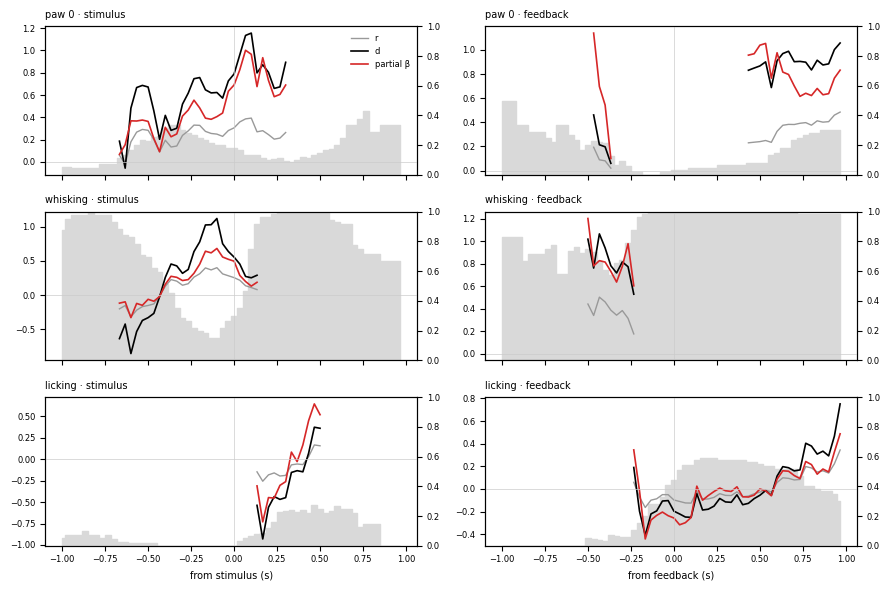

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(9, 6), sharex='col')
for i, feat in enumerate(['paw 0', 'whisking', 'licking']):
    fi = NAMES.index(feat)
    for k, w in enumerate(ns.WINDOWS):
        ax = axes[i, k]
        ax.plot(TIME, row[f'r_{w}'][fi], color='0.6', lw=1, label='r')
        ax.plot(TIME, row[f'd_{w}'][fi], color='k', lw=1.2, label='d')
        ax.plot(TIME, row[f'beta_{w}'][fi], color='C3', lw=1.2, label='partial β')
        ax.axhline(0, color='0.8', lw=0.5); ax.axvline(0, color='0.8', lw=0.5)
        ax2 = ax.twinx(); ax2.fill_between(TIME, 0, row[f'p_{w}'][fi], color='0.85', step='mid', zorder=0)
        ax2.set_ylim(0, 1); ax2.tick_params(labelsize=6)
        ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
        ax.set_title(f'{feat} · {"stimulus" if w == "stim" else "feedback"}', fontsize=7, loc='left')
        ax.tick_params(labelsize=6)
axes[0, 0].legend(fontsize=6, frameon=False)
for ax, lab in zip(axes[-1], ['from stimulus (s)', 'from feedback (s)']):
    ax.set_xlabel(lab, fontsize=7)
plt.tight_layout(); plt.show()

### Syllable vs photometry, one dot per sample

The simplest view. Each dot is one sample: one trial at one timestep, in the stimulus window (blue) or the feedback window (orange). Every unmasked sample with a syllable code is shown, with no minimum number of trials. x is whether the trial is in that feature at that timestep (0 or 1, jittered so the dots spread out). y is the z-scored GCaMP of that trial at that timestep. The line is a least-squares fit over all dots. Its slope is the pooled Δz (mean signal with the feature minus without), and r is the pooled point-biserial correlation, as in notebook 6's "pooled over all samples".

This mixes the time-course relation (a feature and the signal both following the trial's structure, like licking and the reward response) with the trial-to-trial one. Samples from the same trial are not independent, so r describes the plot; it is not a test.

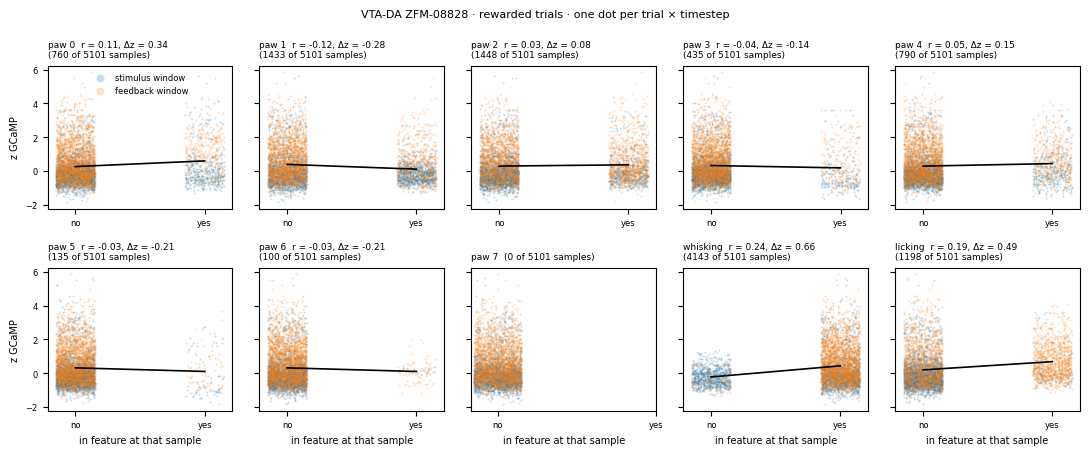

In [6]:
def sample_points(fiber, outcome, features=ns.factored_features):
    # one row per (trial, timestep, window) with a photometry value and a syllable code
    idx = fiber['meta'].index[fiber['meta']['correct'] == outcome].to_numpy()
    pts = []
    for w in ns.WINDOWS:
        P = fiber[w]['photometry'][idx]
        names, F = features(fiber[w]['code'][idx])
        ok = ~np.isnan(P) & ~np.isnan(F[0])
        trial, step = np.nonzero(ok)
        pts.append(pd.DataFrame({'window': w, 'trial': idx[trial], 'time': TIME[step], 'z': P[ok],
                                 **{name: F[k][ok] for k, name in enumerate(names)}}))
    return names, pd.concat(pts, ignore_index=True)

names, pts = sample_points(FIBER, outcome=1)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 5, figsize=(11, 4.6), sharey=True)
for ax, name in zip(axes.flat, names):
    jitter = rng.uniform(-0.15, 0.15, len(pts))
    for w, c in zip(ns.WINDOWS, ['C0', 'C1']):
        m = (pts['window'] == w).to_numpy()
        ax.scatter(pts.loc[m, name] + jitter[m], pts.loc[m, 'z'], s=2, color=c, alpha=0.25, lw=0,
                   label={'stim': 'stimulus window', 'fb': 'feedback window'}[w])
    title = f"{name}  ({int(pts[name].sum())} of {len(pts)} samples)"
    if pts[name].nunique() > 1:
        b = np.polyfit(pts[name], pts['z'], 1)
        ax.plot([0, 1], np.polyval(b, [0, 1]), color='k', lw=1.2)
        title = f"{name}  r = {np.corrcoef(pts[name], pts['z'])[0, 1]:.2f}, Δz = {b[0]:.2f}\n({int(pts[name].sum())} of {len(pts)} samples)"
    ax.set_title(title, fontsize=6.5, loc='left')
    ax.set_xticks([0, 1], ['no', 'yes'], fontsize=6); ax.tick_params(labelsize=6)
for ax in axes[-1]:
    ax.set_xlabel('in feature at that sample', fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel('z GCaMP', fontsize=7)
axes[0, 0].legend(fontsize=6, frameon=False, markerscale=4)
fig.suptitle(f"{FIBER['meta']['target_NM'].iat[0]} {FIBER['meta']['subject'].iat[0]} · rewarded trials · one dot per trial × timestep", fontsize=8)
plt.tight_layout(); plt.show()

### Continuous movement vs photometry, one dot per sample

The same plot, but on the continuous signals the syllables were built from. x is now a real quantity:
- **paw speed**: left-paw speed from the pose x/y, in px/s, shown as log10(1 + ·);
- **wheel speed**: |wheel velocity|, shown as log10(1 + ·);
- **whisker ME**: whisker-pad motion energy, in raw units;
- **lick rate**: licks/s. `Lick count` is a 0/1 lick event per 30 Hz bin, so it is counted over a centred ~233 ms window (`ns.LICK_WINDOW`).

Each dot is one trial at one timestep (blue: stimulus window, orange: feedback window). The line is a least-squares fit over all dots, and r is their correlation. The same caveats apply: it mixes timing with trial-to-trial variation, and samples within a trial are not independent.

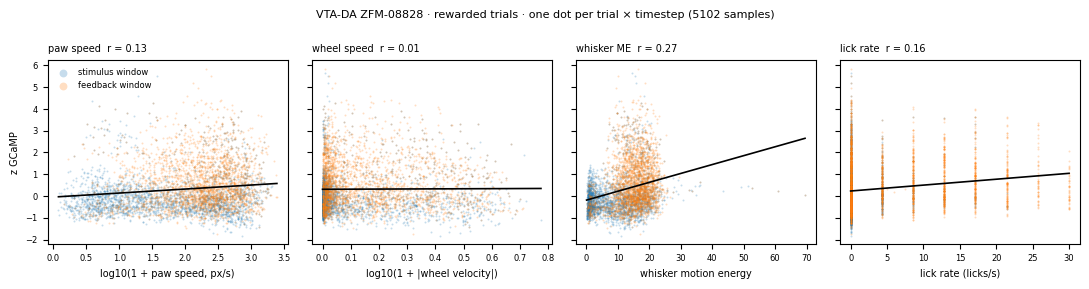

In [7]:
SIGNALS = [('paw speed', 'log10(1 + paw speed, px/s)', np.log10), ('wheel speed', 'log10(1 + |wheel velocity|)', np.log10),
           ('whisker ME', 'whisker motion energy', None), ('lick rate', 'lick rate (licks/s)', None)]

def movement_points(fiber, outcome):
    idx = fiber['meta'].index[fiber['meta']['correct'] == outcome].to_numpy()
    pts = []
    for w in ns.WINDOWS:
        P, M = fiber[w]['photometry'][idx], fiber[w]['movement']
        ok = ~np.isnan(P) & np.all([~np.isnan(M[s][idx]) for s, _, _ in SIGNALS], axis=0)
        pts.append(pd.DataFrame({'window': w, 'z': P[ok], **{s: M[s][idx][ok] for s, _, _ in SIGNALS}}))
    return pd.concat(pts, ignore_index=True)

mp = movement_points(FIBER, outcome=1)
fig, axes = plt.subplots(1, 4, figsize=(11, 2.9), sharey=True)
for ax, (s, label, f) in zip(axes, SIGNALS):
    x = f(1 + mp[s]) if f is not None else mp[s]
    for w, c in zip(ns.WINDOWS, ['C0', 'C1']):
        m = (mp['window'] == w).to_numpy()
        ax.scatter(x[m], mp.loc[m, 'z'], s=2, color=c, alpha=0.25, lw=0,
                   label={'stim': 'stimulus window', 'fb': 'feedback window'}[w])
    b = np.polyfit(x, mp['z'], 1)
    xs = np.array([x.min(), x.max()])
    ax.plot(xs, np.polyval(b, xs), color='k', lw=1.2)
    ax.set_title(f'{s}  r = {np.corrcoef(x, mp["z"])[0, 1]:.2f}', fontsize=7, loc='left')
    ax.set_xlabel(label, fontsize=7); ax.tick_params(labelsize=6)
axes[0].set_ylabel('z GCaMP', fontsize=7)
axes[0].legend(fontsize=6, frameon=False, markerscale=4)
fig.suptitle(f"{FIBER['meta']['target_NM'].iat[0]} {FIBER['meta']['subject'].iat[0]} · rewarded trials · "
             f"one dot per trial × timestep ({len(mp)} samples)", fontsize=8)
plt.tight_layout(); plt.show()

### Extended covariates

Here β also holds fixed previous outcome, choice side and block congruence. These are the obvious task drivers of dopamine besides movement. The map shows how much of the task-covariate β they take away (task β − extended β, same colour scale as β).

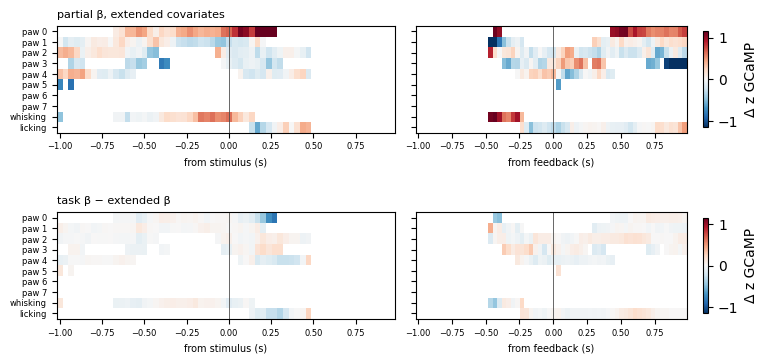

In [8]:
rx = EM['extended'].query('outcome == 1').iloc[0]
fig = plt.figure(figsize=(9, 3.8)); gs = fig.add_gridspec(2, 1, hspace=0.75)
lim = np.nanpercentile(np.abs(np.concatenate([row['beta_stim'].ravel(), row['beta_fb'].ravel()])), 98)
map_pair(fig, gs[0], [rx['beta_stim'], rx['beta_fb']], 'partial β, extended covariates', lim=lim, cbar_label='Δ z GCaMP')
map_pair(fig, gs[1], [row['beta_stim'] - rx['beta_stim'], row['beta_fb'] - rx['beta_fb']], 'task β − extended β',
         lim=lim, cbar_label='Δ z GCaMP')
plt.show()

## 2. Joint model: each feature's unique effect

The marginal maps above test one feature at a time. But the features overlap: the paw states sum to 1, and whisking goes with the active paw states. `ns.joint_maps` puts them all in one regression per sample: paw states 1–7 against paw 0 (stillest), plus whisking, licking and the task covariates. A feature rarer than 5 trials at a sample is left out of that sample's model. The β of whisking is now its effect at a fixed paw state, and the reverse for the paw states.

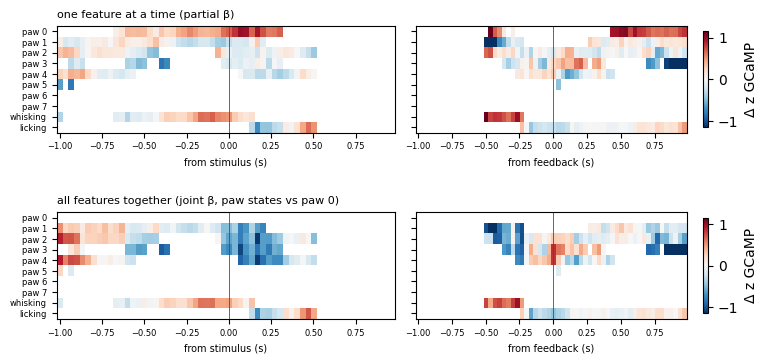

In [9]:
JM = ns.joint_maps(FIBER)
jr = JM.query('outcome == 1').iloc[0]
fig = plt.figure(figsize=(9, 3.8)); gs = fig.add_gridspec(2, 1, hspace=0.75)
lim = np.nanpercentile(np.abs(np.concatenate([row['beta_stim'].ravel(), row['beta_fb'].ravel()])), 98)
map_pair(fig, gs[0], [row['beta_stim'], row['beta_fb']], 'one feature at a time (partial β)', lim=lim, cbar_label='Δ z GCaMP')
map_pair(fig, gs[1], [jr['beta_stim'], jr['beta_fb']], 'all features together (joint β, paw states vs paw 0)', lim=lim,
         cbar_label='Δ z GCaMP')
plt.show()

## 3. Syllable identity vs continuous vigor

Does the NM track *which* syllable the mouse is in, or just *how much* it moves? At each sample, four nested ridge models of the photometry are fitted (α = 1, standardised predictors) and scored by 5-fold cross-validated R² across trials:
1. task covariates only;
2. \+ vigor: log(1 + ·) of paw speed, wheel speed, whisker motion energy and lick count at that sample;
3. \+ syllables: the factored one-hots;
4. \+ both.

Unique syllable variance = R²(4) − R²(2). Unique vigor variance = R²(4) − R²(3).

On 61 trials, ~20 predictors overfit, so the R² values go negative. These figures check the code, not the result. With full sessions (~700 trials), they become informative.

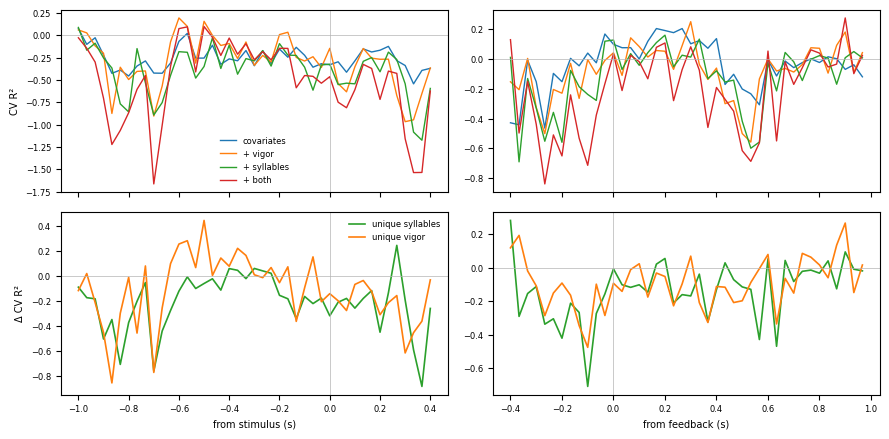

In [10]:
VP = ns.variance_partition(FIBER)
vr = VP.query('outcome == 1').iloc[0]
fig, axes = plt.subplots(2, 2, figsize=(9, 4.5), sharex='col')
for k, w in enumerate(ns.WINDOWS):
    R = vr[f'r2_{w}']
    for m, name in enumerate(VP.attrs['models']):
        axes[0, k].plot(TIME, R[m], lw=1, label=name)
    axes[1, k].plot(TIME, R[3] - R[1], color='C2', lw=1.2, label='unique syllables')
    axes[1, k].plot(TIME, R[3] - R[2], color='C1', lw=1.2, label='unique vigor')
    for ax in axes[:, k]:
        ax.axhline(0, color='0.7', lw=0.5); ax.axvline(0, color='0.7', lw=0.5); ax.tick_params(labelsize=6)
    axes[1, k].set_xlabel(['from stimulus (s)', 'from feedback (s)'][k], fontsize=7)
axes[0, 0].set_ylabel('CV R²', fontsize=7); axes[1, 0].set_ylabel('Δ CV R²', fontsize=7)
axes[0, 0].legend(fontsize=6, frameon=False); axes[1, 0].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()

## Scaling up

Every function runs per fiber and returns one row per outcome, with the maps as arrays. Across sessions, concatenate the rows, cache them with `to_pickle` (not parquet: the cells hold arrays), and pass them to `ns.summarise(table, 'beta_stim')`. That gives mice as the unit: the per-mouse mean, then a t-test across mice and FDR over the map, which needs ≥ 3 mice.

```python
EM_ALL = pd.concat([ns.effect_maps(f) for eid in rec['eid'].unique() for f in ns.load_session(eid)], ignore_index=True)
S = ns.summarise(EM_ALL, 'beta_stim')   # {(target_NM, outcome): mean, mice, t, q, n_mice, n_sessions}
```